# Learning MNIST with neural networks

**Description**: neural networks represent the state of the art in modern machine learning. They have extensive application in classification and regression problems. Their architecture can be quite complicated. Here, I focus on the standard MNIST classification of handwirtten digits.

**Goal**: classify handwritten digits of the MNIST database by building a neural network from scratch.

## Import libraries and load data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import neural_network as nn
import mnist_loader

from importlib import reload

In [2]:
# Reload nn module
reload(nn)

<module 'neural_network' from '/home/nf/Projects/ML-intro/NN_MNIST_from_scratch/src/neural_network.py'>

In [3]:
train_data, validation_data, test_data = mnist_loader.load_data_wrapper()

## Build the network

In [4]:
# Generate network with 30 hidden neurons
# 784 = 28 x 28 neurons from input images
# 10 output neurons corresponding to output digits
net = nn.NeuralNetwork([784, 30, 10])

## Train the network

First, define the variables defining mini-batch size, number of epochs, and learning rate $\eta$

In [5]:
# Mini-batch size
mini_batch_size = 10

# Epochs
epochs = 30

# Learning rate
eta = 3.0

In [6]:
# SGD training
net.SGD(train_data, epochs, mini_batch_size, eta, test_data=test_data)

Epoch 0: 9149/10000
Epoch 1: 9165/10000
Epoch 2: 9342/10000
Epoch 3: 9386/10000
Epoch 4: 9441/10000
Epoch 5: 9424/10000
Epoch 6: 9433/10000
Epoch 7: 9490/10000
Epoch 8: 9456/10000
Epoch 9: 9465/10000
Epoch 10: 9476/10000
Epoch 11: 9486/10000
Epoch 12: 9493/10000
Epoch 13: 9491/10000
Epoch 14: 9492/10000
Epoch 15: 9471/10000
Epoch 16: 9487/10000
Epoch 17: 9508/10000
Epoch 18: 9502/10000
Epoch 19: 9505/10000
Epoch 20: 9532/10000
Epoch 21: 9507/10000
Epoch 22: 9510/10000
Epoch 23: 9525/10000
Epoch 24: 9513/10000
Epoch 25: 9525/10000
Epoch 26: 9511/10000
Epoch 27: 9504/10000
Epoch 28: 9519/10000
Epoch 29: 9533/10000


In [7]:
# Let's increase hidden neurons to 100
net2 = nn.NeuralNetwork([784, 100, 10])
net2.SGD(train_data, epochs, mini_batch_size, eta, test_data=test_data)

Epoch 0: 5808/10000
Epoch 1: 6658/10000
Epoch 2: 7567/10000
Epoch 3: 7609/10000
Epoch 4: 7636/10000
Epoch 5: 7680/10000
Epoch 6: 7686/10000
Epoch 7: 7707/10000
Epoch 8: 7703/10000
Epoch 9: 7727/10000
Epoch 10: 7733/10000
Epoch 11: 7713/10000
Epoch 12: 7742/10000
Epoch 13: 7733/10000
Epoch 14: 7729/10000
Epoch 15: 7754/10000
Epoch 16: 7747/10000
Epoch 17: 7749/10000
Epoch 18: 7754/10000
Epoch 19: 7766/10000
Epoch 20: 7747/10000
Epoch 21: 7743/10000
Epoch 22: 7758/10000
Epoch 23: 7758/10000
Epoch 24: 7750/10000
Epoch 25: 7761/10000
Epoch 26: 7751/10000
Epoch 27: 7765/10000
Epoch 28: 7758/10000
Epoch 29: 7764/10000


In [8]:
# Exercise: input-output layers only
net3 = nn.NeuralNetwork([784, 10])
net3.SGD(train_data, epochs, mini_batch_size, eta, test_data=test_data)

Epoch 0: 6585/10000
Epoch 1: 6611/10000
Epoch 2: 6648/10000
Epoch 3: 6660/10000
Epoch 4: 6651/10000
Epoch 5: 6668/10000
Epoch 6: 6668/10000
Epoch 7: 6668/10000
Epoch 8: 6681/10000
Epoch 9: 6668/10000
Epoch 10: 6675/10000
Epoch 11: 6697/10000
Epoch 12: 6703/10000
Epoch 13: 6701/10000
Epoch 14: 6696/10000
Epoch 15: 6729/10000
Epoch 16: 6713/10000
Epoch 17: 6698/10000
Epoch 18: 6692/10000
Epoch 19: 6727/10000
Epoch 20: 6746/10000
Epoch 21: 6747/10000
Epoch 22: 6783/10000
Epoch 23: 7519/10000
Epoch 24: 7580/10000
Epoch 25: 7566/10000
Epoch 26: 7575/10000
Epoch 27: 7549/10000
Epoch 28: 7572/10000
Epoch 29: 7596/10000


In [2]:
%run mnist_svm.py

Baseline classifier using an SVM.
9785 of 10000 values correct.


The simple one-leayer network reported an accuracy around 95%! \
Ready-to-use SVM has an accuracy of 97.8%, however there is much room for improvement! 

## Getting a better network

The network is improved:
- considering the cross-entropy as a the loss function
- introducing regularization method (L1, L2, dropout, artificial expansion of training data)
- improving initial weights and biases
- choosing (heuristically) better hyperparameters

In [6]:
import better_network as bnet

In [7]:
reload(bnet)

<module 'better_network' from '/home/nf/Projects/ML-intro/NN_MNIST_from_scratch/src/better_network.py'>

In [10]:
epochs = 100
mini_batch_size = 10
eta = 0.5

### Cross-entropy

In [41]:
bench_net_cross = bnet.Network([784, 30, 10], cost=bnet.CrossEntropyCost)
bench_net_cross.large_weight_initializer()
val_cost, val_acc, train_cost, train_acc = bench_net_cross.SGD(train_data, epochs, mini_batch_size, eta, evaluation_data=test_data, monitor_training_cost=True, monitor_training_accuracy=True, monitor_evaluation_cost=True, monitor_evaluation_accuracy=True)

Epoch 0 training complete
Cost on training data: 0.5542663152820159
Accuracy on training data: 45661 / 50000
Cost on evaluation data: 0.5552127029393237
Accuracy on evaluation data: 9144 / 10000

Epoch 1 training complete
Cost on training data: 0.4376460457614117
Accuracy on training data: 46689 / 50000
Cost on evaluation data: 0.45541031095918627
Accuracy on evaluation data: 9311 / 10000

Epoch 2 training complete
Cost on training data: 0.4062970977262453
Accuracy on training data: 46893 / 50000
Cost on evaluation data: 0.43874488782271
Accuracy on evaluation data: 9336 / 10000

Epoch 3 training complete
Cost on training data: 0.3405282160760833
Accuracy on training data: 47436 / 50000
Cost on evaluation data: 0.39851240954678235
Accuracy on evaluation data: 9379 / 10000

Epoch 4 training complete
Cost on training data: 0.3207466964864655
Accuracy on training data: 47667 / 50000
Cost on evaluation data: 0.37414258564546243
Accuracy on evaluation data: 9442 / 10000

Epoch 5 training co

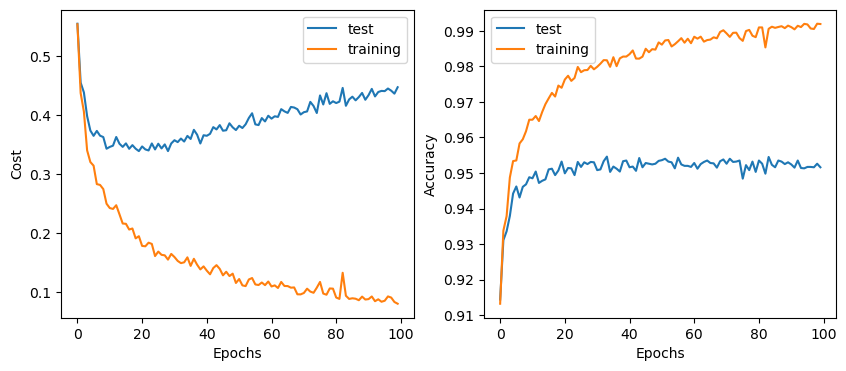

In [45]:
# Convert to percentage
val_acc_perc = [x/10000 for x in val_acc]
train_acc_perc = [x/50000 for x in train_acc]

fig=plt.figure(figsize=(10,4))
ax1=fig.add_subplot(121)
ax2=fig.add_subplot(122)
ax1.plot(val_cost, label='test')
ax1.plot(train_cost, label='training')
ax1.set_ylabel('Cost')
ax1.set_xlabel('Epochs')
ax1.legend(loc='best')
ax2.set_ylabel('Accuracy')
ax2.plot(val_acc_perc, label='test')
ax2.plot(train_acc_perc, label='training')
ax2.set_xlabel('Epochs')
ax2.legend(loc='best')

The cost function decreases for the training data while it reaches a minimim for the test data around epoch 20, and then increases again. This behavior points to overfitting, as the network memorizes the training features but fails to generalize on test data.\
The test accuracy is around the value, 95%, with quadratic cost function. However, there is a difference of 4% between training and test dataset. The training data has an accuracy of 99%, remarkably larger than test accuracy. This is another hint for overfitting.\
The overfitting problem is expected since we only changed the cost function, which helps with avoiding slow learning. However, it does not necessarily help with overfitting.

### Cross-Entropy + L2 Regularization

In [8]:
bench_net_cross = bnet.Network([784, 30, 10], cost=bnet.CrossEntropyCost)
bench_net_cross.large_weight_initializer()
val_cost, val_acc, train_cost, train_acc = bench_net_cross.SGD(train_data, epochs, mini_batch_size, eta, lmbda=5.0, evaluation_data=test_data, monitor_training_cost=True, monitor_training_accuracy=True, monitor_evaluation_cost=True, monitor_evaluation_accuracy=True)

Epoch 0 training complete
Cost on training data: 1.327982182195024
Accuracy on training data: 45451 / 50000
Cost on evaluation data: 4.360311063209434
Accuracy on evaluation data: 9058 / 10000

Epoch 1 training complete
Cost on training data: 0.9350659727953523
Accuracy on training data: 46801 / 50000
Cost on evaluation data: 2.9329325090898806
Accuracy on evaluation data: 9312 / 10000

Epoch 2 training complete
Cost on training data: 0.6953807706371482
Accuracy on training data: 47430 / 50000
Cost on evaluation data: 2.092628343233253
Accuracy on evaluation data: 9448 / 10000

Epoch 3 training complete
Cost on training data: 0.5807798437854303
Accuracy on training data: 47650 / 50000
Cost on evaluation data: 1.613306368986978
Accuracy on evaluation data: 9482 / 10000

Epoch 4 training complete
Cost on training data: 0.5218343325050623
Accuracy on training data: 47727 / 50000
Cost on evaluation data: 1.35051159297984
Accuracy on evaluation data: 9497 / 10000

Epoch 5 training complete


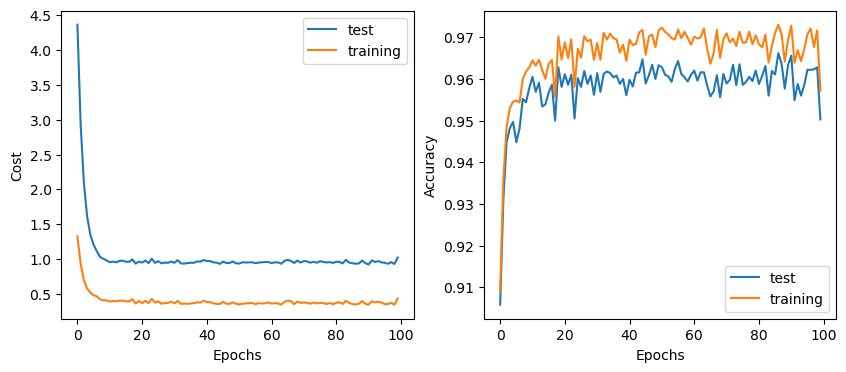

In [9]:
# Convert to percentage
val_acc_perc = [x/10000 for x in val_acc]
train_acc_perc = [x/50000 for x in train_acc]

fig=plt.figure(figsize=(10,4))
ax1=fig.add_subplot(121)
ax2=fig.add_subplot(122)
ax1.plot(val_cost, label='test')
ax1.plot(train_cost, label='training')
ax1.set_ylabel('Cost')
ax1.set_xlabel('Epochs')
ax1.legend(loc='best')
ax2.set_ylabel('Accuracy')
ax2.plot(val_acc_perc, label='test')
ax2.plot(train_acc_perc, label='training')
ax2.set_xlabel('Epochs')
ax2.legend(loc='best')

Regularization strongly improves the network. The test cost function behaves more regularly, without any local minima. The test accuracy differs by 1% from the training accuracy and it has a large value, around 96%. The network has improved in learning and generalizing. L2 regularization penalizes large weights, and the network is more "controlled". It avoids wild oscillation typical of noise fitting.

### Cross-entropy+regularization+weight initialization

In [18]:
eta = 0.1
epochs = 30

In [19]:
bench_net_cross = bnet.Network([784, 30, 10], cost=bnet.CrossEntropyCost)
bench_net_cross.large_weight_initializer()
val_cost_slow, val_acc_slow, train_cost_slow, train_acc_slow = bench_net_cross.SGD(train_data, epochs, mini_batch_size, eta, lmbda=5.0, evaluation_data=test_data, monitor_training_cost=True, monitor_training_accuracy=True, monitor_evaluation_cost=True, monitor_evaluation_accuracy=True)

Epoch 0 training complete
Cost on training data: 1.992938354982029
Accuracy on training data: 42866 / 50000
Cost on evaluation data: 6.327941736533955
Accuracy on evaluation data: 8633 / 10000

Epoch 1 training complete
Cost on training data: 1.6820512926971805
Accuracy on training data: 44721 / 50000
Cost on evaluation data: 5.640697133298259
Accuracy on evaluation data: 8984 / 10000

Epoch 2 training complete
Cost on training data: 1.488495289119093
Accuracy on training data: 45633 / 50000
Cost on evaluation data: 5.101434397874867
Accuracy on evaluation data: 9142 / 10000

Epoch 3 training complete
Cost on training data: 1.3495538928208102
Accuracy on training data: 46134 / 50000
Cost on evaluation data: 4.644802198651328
Accuracy on evaluation data: 9211 / 10000

Epoch 4 training complete
Cost on training data: 1.2254357084349918
Accuracy on training data: 46485 / 50000
Cost on evaluation data: 4.237024744558646
Accuracy on evaluation data: 9272 / 10000

Epoch 5 training complete
C

In [20]:
bench_net_cross = bnet.Network([784, 30, 10], cost=bnet.CrossEntropyCost)
val_cost_fast, val_acc_fast, train_cost_fast, train_acc_fast = bench_net_cross.SGD(train_data, epochs, mini_batch_size, eta, lmbda=5.0, evaluation_data=test_data, monitor_training_cost=True, monitor_training_accuracy=True, monitor_evaluation_cost=True, monitor_evaluation_accuracy=True)

Epoch 0 training complete
Cost on training data: 0.5692412345211108
Accuracy on training data: 45997 / 50000
Cost on evaluation data: 0.6851775910363835
Accuracy on evaluation data: 9244 / 10000

Epoch 1 training complete
Cost on training data: 0.47013543818806863
Accuracy on training data: 46887 / 50000
Cost on evaluation data: 0.6459867902643216
Accuracy on evaluation data: 9370 / 10000

Epoch 2 training complete
Cost on training data: 0.4449774107593447
Accuracy on training data: 47096 / 50000
Cost on evaluation data: 0.6653658026413741
Accuracy on evaluation data: 9397 / 10000

Epoch 3 training complete
Cost on training data: 0.4083774508174185
Accuracy on training data: 47477 / 50000
Cost on evaluation data: 0.6661076971526849
Accuracy on evaluation data: 9452 / 10000

Epoch 4 training complete
Cost on training data: 0.38672660087203564
Accuracy on training data: 47744 / 50000
Cost on evaluation data: 0.6693584073539889
Accuracy on evaluation data: 9501 / 10000

Epoch 5 training c

(0.85, 1.0)

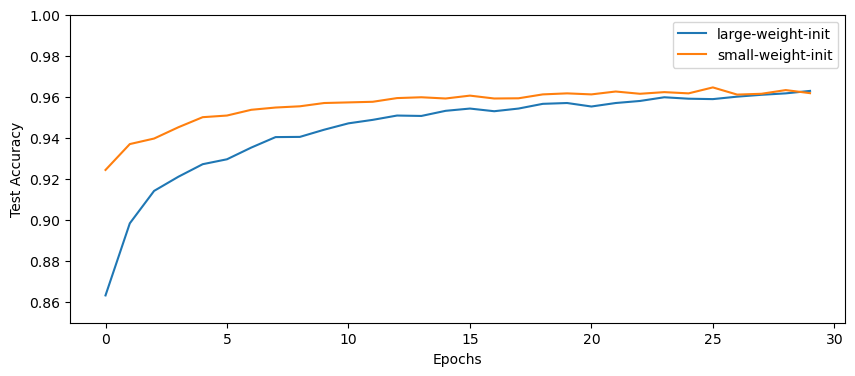

In [21]:
# Convert to percentage
val_acc_slow_perc = [x/10000 for x in val_acc_slow]
val_acc_fast_perc = [x/10000 for x in val_acc_fast]

fig=plt.figure(figsize=(10,4))
ax1=fig.add_subplot(111)
ax1.plot(val_acc_slow_perc, label='large-weight-init')
ax1.plot(val_acc_fast_perc, label='small-weight-init')
ax1.set_ylabel('Test Accuracy')
ax1.set_xlabel('Epochs')
ax1.legend(loc='best')
ax1.set_ylim(0.85,1)

New initialization of weights improves the learning of the network. In particular, the network reaches the target accuracy faster than the case of "large" weights drawn from gaussian distribution with unitar standard deviation